In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("🚀 A preparar dados e a treinar o modelo Baseline (Regressão Logística)...")

# 1. Carregar e limpar dados
df = pd.read_csv('../data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv')
df.columns = df.columns.str.strip()

cols_to_drop = [
    'Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Timestamp',
    'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 
    'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 
    'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate'
]
df_clean = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
df_clean = df_clean.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates()
df_clean['Label_Num'] = df_clean['Label'].map({'BENIGN': 0, 'DDoS': 1})

# 2. Divisão e Escalonamento
X = df_clean.drop(columns=['Label', 'Label_Num'])
y = df_clean['Label_Num']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Treinar Regressão Logística
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

# 4. Avaliar Previsões
y_pred_lr = lr_model.predict(X_test_scaled)

print(f"\n✅ Treino Concluído!")
print(f"• Exatidão (Accuracy): {accuracy_score(y_test, y_pred_lr) * 100:.2f}%\n")
print("--- Relatório de Desempenho ---")
print(classification_report(y_test, y_pred_lr, target_names=['BENIGN', 'DDoS']))


🚀 A preparar dados e a treinar o modelo Baseline (Regressão Logística)...

✅ Treino Concluído!
• Exatidão (Accuracy): 99.85%

--- Relatório de Desempenho ---
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     18650
        DDoS       1.00      1.00      1.00     25603

    accuracy                           1.00     44253
   macro avg       1.00      1.00      1.00     44253
weighted avg       1.00      1.00      1.00     44253



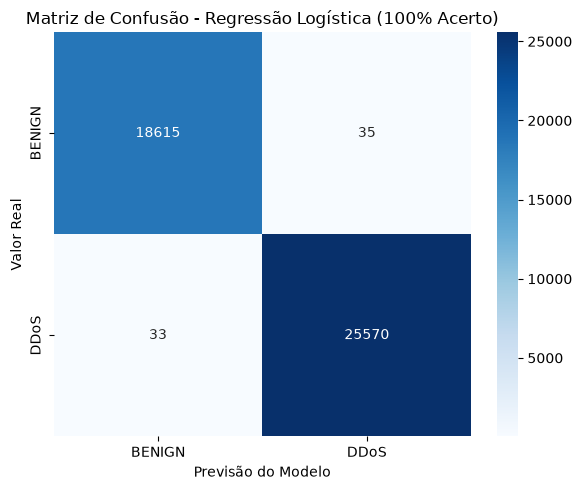

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

# Criar a Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['BENIGN', 'DDoS'], 
            yticklabels=['BENIGN', 'DDoS'])

plt.xlabel('Previsão do Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusão - Regressão Logística (100% Acerto)')
plt.tight_layout()
plt.show()